# 02 – Modeling & explainability: high mammographic density

Data: `model_menohrt_{train,test}.parquet` from `src/prepare.py` (no `year`, `meno_hrt` replaces `menopaus` + `current_hrt`,
missing values as their own category). Rows are aggregated covariate patterns. `sample_weight` = number of mammograms with
that pattern, used as a weight everywhere (fits, CV, metrics, SHAP summaries).

In [1]:
import itertools
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import xgboost as xgb
import shap
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from prepare import MENO_HRT_FEATURES, TARGET, WEIGHT

PROCESSED = ROOT / "data/processed"
FIG_DIR = ROOT / "output"
train = pd.read_parquet(PROCESSED / "model_menohrt_train.parquet")
test = pd.read_parquet(PROCESSED / "model_menohrt_test.parquet")
FEATURES = [c for c in train.columns if c not in (TARGET, WEIGHT)]
X_tr, y_tr, w_tr = train[FEATURES], train[TARGET], train[WEIGHT]
X_te, y_te, w_te = test[FEATURES], test[TARGET], test[WEIGHT]

# map each one-hot column back to its source variable
VAR_OF = {c: next(v for v in MENO_HRT_FEATURES if c.startswith(v + "_")) for c in FEATURES}
LEVEL_OF = {c: c[len(VAR_OF[c]) + 1:] for c in FEATURES}
print(f"train: {len(train):,} patterns / {w_tr.sum():,} mammograms; test: {len(test):,} / {w_te.sum():,}")

train: 141,403 patterns / 4,804,953 mammograms; test: 88,850 / 1,223,806


## 1. Baseline: weighted logistic regression

Binomial GLM with frequency weights. Reference level per variable = its most common known category (by weight).
Odds ratios (OR) are relative to that reference, adjusted for all other variables.

**Caveat:** frequency weights treat every mammogram as independent. Women contribute several mammograms, so the
CIs are too narrow — read them as "precisely estimated", not as exact 95% coverage.

In [2]:
reference = {}
for var in MENO_HRT_FEATURES:
    cols = [c for c in FEATURES if VAR_OF[c] == var and LEVEL_OF[c] != "Unknown"]
    reference[var] = max(cols, key=lambda c: (X_tr[c] * w_tr).sum())
LR_COLS = [c for c in FEATURES if c not in reference.values()]

glm = sm.GLM(y_tr, sm.add_constant(X_tr[LR_COLS]), family=sm.families.Binomial(), freq_weights=w_tr).fit()
ci = glm.conf_int()
or_table = pd.DataFrame({
    "variable": [VAR_OF[c] for c in LR_COLS],
    "category": [LEVEL_OF[c] for c in LR_COLS],
    "reference": [LEVEL_OF[reference[VAR_OF[c]]] for c in LR_COLS],
    "OR": np.exp(glm.params[LR_COLS]),
    "CI_low": np.exp(ci.loc[LR_COLS, 0]),
    "CI_high": np.exp(ci.loc[LR_COLS, 1]),
    "p": glm.pvalues[LR_COLS],
}).reset_index(drop=True)
or_table.to_csv(PROCESSED / "lr_odds_ratios.csv", index=False)
pd.set_option("display.max_rows", 100)
or_table.style.format({"OR": "{:.2f}", "CI_low": "{:.2f}", "CI_high": "{:.2f}", "p": "{:.1e}"})

,variable,category,reference,OR,CI_low,CI_high,p
0,age_group_5_years,18-29,50-54,2.25,2.13,2.38,8.0e-184
1,age_group_5_years,30-34,50-54,2.21,2.15,2.27,0.0e+00
2,age_group_5_years,35-39,50-54,1.87,1.84,1.89,0.0e+00
3,age_group_5_years,40-44,50-54,1.68,1.67,1.69,0.0e+00
4,age_group_5_years,45-49,50-54,1.48,1.47,1.50,0.0e+00
5,age_group_5_years,55-59,50-54,0.74,0.73,0.74,0.0e+00
6,age_group_5_years,60-64,50-54,0.63,0.63,0.64,0.0e+00
7,age_group_5_years,65-69,50-54,0.54,0.54,0.55,0.0e+00
8,age_group_5_years,70-74,50-54,0.49,0.49,0.49,0.0e+00
9,age_group_5_years,75-79,50-54,0.45,0.45,0.46,0.0e+00


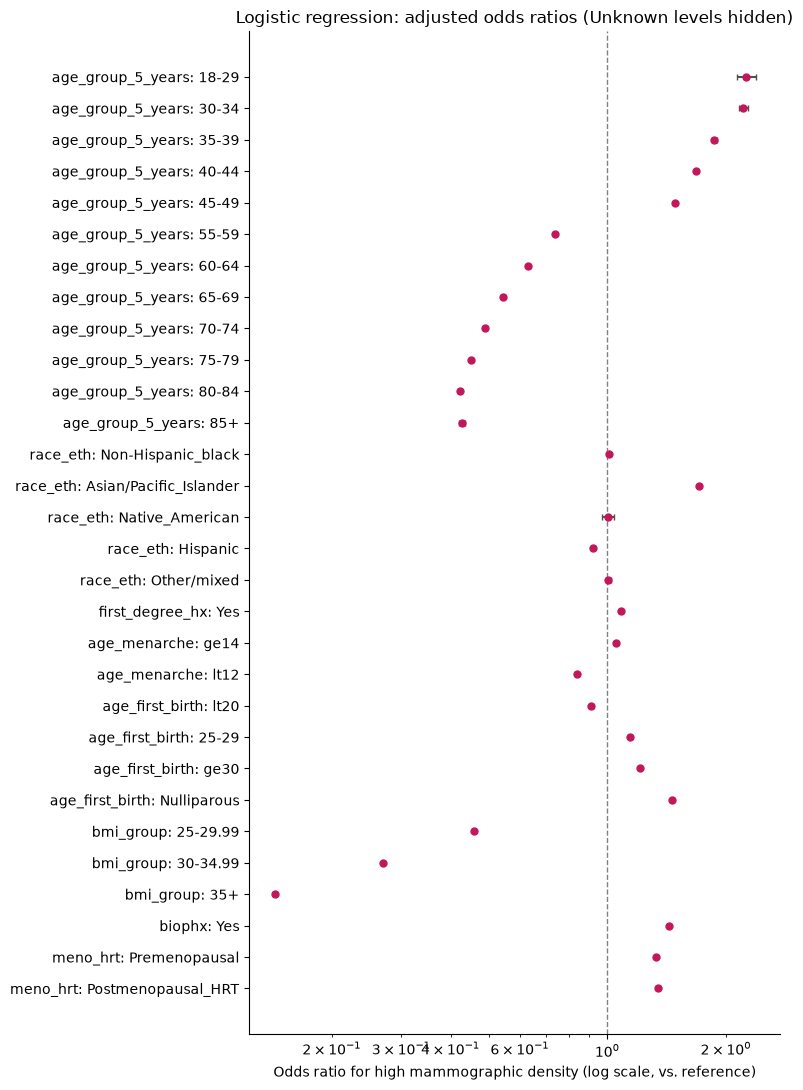

In [3]:
known = or_table[or_table["category"] != "Unknown"].iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 11))
ypos = np.arange(len(known))
ax.errorbar(known["OR"], ypos, xerr=[known["OR"] - known["CI_low"], known["CI_high"] - known["OR"]],
            fmt="o", ms=5, color="#c2185b", ecolor="#52514e", capsize=2)
ax.axvline(1, color="grey", lw=1, ls="--")
ax.set_yticks(ypos, known["variable"] + ": " + known["category"])
ax.set_xscale("log")
ax.set_xlabel("Odds ratio for high mammographic density (log scale, vs. reference)")
ax.set_title("Logistic regression: adjusted odds ratios (Unknown levels hidden)")
sns.despine()
fig.tight_layout()

## 2. XGBoost with sample weights, light tuning via 5-fold CV

Small grid over depth, learning rate and min_child_weight; number of trees chosen by early stopping inside stratified 5-fold CV
(weighted log loss).

In [4]:
dtrain = xgb.DMatrix(X_tr, label=y_tr, weight=w_tr)
base = {"objective": "binary:logistic", "eval_metric": "logloss", "tree_method": "hist",
        "subsample": 0.8, "colsample_bytree": 0.8, "seed": 42}
results = []
for max_depth, eta, mcw in itertools.product((2, 3, 4), (0.05, 0.1), (1, 100)):
    params = {**base, "max_depth": max_depth, "eta": eta, "min_child_weight": mcw}
    cv = xgb.cv(params, dtrain, num_boost_round=2000, nfold=5, stratified=True,
                early_stopping_rounds=50, seed=42)
    results.append({"max_depth": max_depth, "eta": eta, "min_child_weight": mcw, "n_trees": len(cv),
                    "cv_logloss": cv["test-logloss-mean"].iloc[-1], "cv_sd": cv["test-logloss-std"].iloc[-1]})
cv_results = pd.DataFrame(results).sort_values("cv_logloss")
cv_results

,max_depth,eta,min_child_weight,n_trees,cv_logloss,cv_sd
2,2,0.10,1,134,0.622938,0.007400
3,2,0.10,100,134,0.622938,0.007401
0,2,0.05,1,341,0.623044,0.007653
1,2,0.05,100,341,0.623044,0.007653
6,3,0.10,1,72,0.625805,0.006902
7,3,0.10,100,72,0.625806,0.006899
4,3,0.05,1,115,0.626275,0.006977
5,3,0.05,100,115,0.626276,0.006977
10,4,0.10,1,37,0.630370,0.006030
11,4,0.10,100,37,0.630438,0.005948


In [5]:
best = cv_results.iloc[0]
best_params = {**base, "max_depth": int(best["max_depth"]), "eta": float(best["eta"]),
               "min_child_weight": int(best["min_child_weight"])}
booster = xgb.train(best_params, dtrain, num_boost_round=int(best["n_trees"]))
booster.save_model(PROCESSED / "xgb_menohrt.json")
print("best:", {k: best_params[k] for k in ("max_depth", "eta", "min_child_weight")}, "trees:", int(best["n_trees"]))

best: {'max_depth': 2, 'eta': 0.1, 'min_child_weight': 1} trees: 134


## 3. Weighted test-set metrics

In [6]:
pred = {
    "Logistic regression": glm.predict(sm.add_constant(X_te[LR_COLS], has_constant="add")).to_numpy(),
    "XGBoost": booster.predict(xgb.DMatrix(X_te)),
}
prevalence = np.average(y_te, weights=w_te)
metrics = pd.DataFrame({
    name: {"ROC AUC": roc_auc_score(y_te, p, sample_weight=w_te),
           "PR AUC (avg. precision)": average_precision_score(y_te, p, sample_weight=w_te),
           "Brier score": brier_score_loss(y_te, p, sample_weight=w_te)}
    for name, p in pred.items()
}).T
metrics.loc["No-skill reference"] = [0.5, prevalence, prevalence * (1 - prevalence)]
metrics.to_csv(PROCESSED / "test_metrics.csv")
metrics.round(4)

,ROC AUC,PR AUC (avg. precision),Brier score
Logistic regression,0.7204,0.6954,0.2123
XGBoost,0.7202,0.6946,0.2124
No-skill reference,0.5000,0.4677,0.2490


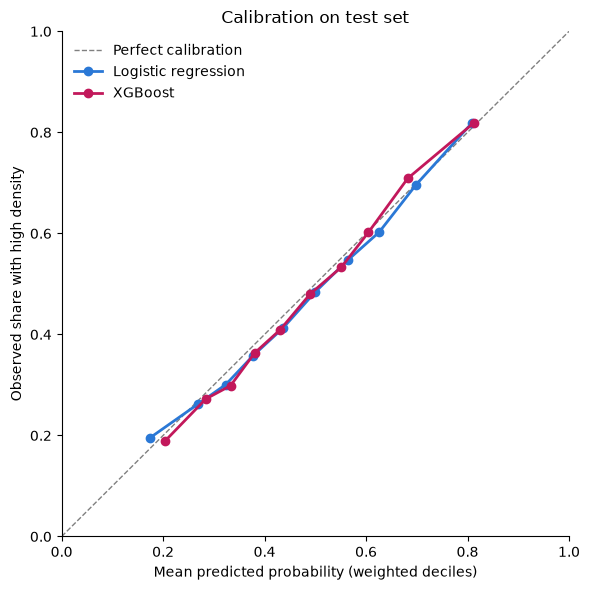

In [7]:
def weighted_calibration(y, p, w, n_bins=10):
    order = np.argsort(p)
    cum = np.cumsum(w.to_numpy()[order]) / w.sum()
    bins = np.minimum((cum * n_bins).astype(int), n_bins - 1)  # equal-weight bins
    df = pd.DataFrame({"bin": bins, "p": p[order], "y": y.to_numpy()[order], "w": w.to_numpy()[order]})
    return df.groupby("bin").apply(lambda g: pd.Series({"mean_pred": np.average(g.p, weights=g.w),
                                                        "obs_rate": np.average(g.y, weights=g.w)}))

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], ls="--", c="grey", lw=1, label="Perfect calibration")
for (name, p), color in zip(pred.items(), ["#2a78d6", "#c2185b"]):
    cal = weighted_calibration(y_te, p, w_te)
    ax.plot(cal["mean_pred"], cal["obs_rate"], marker="o", lw=2, color=color, label=name)
ax.set(xlabel="Mean predicted probability (weighted deciles)", ylabel="Observed share with high density",
       title="Calibration on test set", xlim=(0, 1), ylim=(0, 1))
ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration.png", dpi=150)

## 4. SHAP

TreeExplainer on the XGBoost model, all test patterns (values in log-odds). One-hot columns are summed back to
their source variable, so each variable gets one SHAP value per row. Importances are weighted by `sample_weight`.

In [8]:
explainer = shap.TreeExplainer(booster)
sv = explainer.shap_values(X_te)
sv_df = pd.DataFrame(sv, columns=FEATURES)
sv_var = sv_df.T.groupby(pd.Series(VAR_OF)).sum().T[MENO_HRT_FEATURES]

importance = (sv_var.abs().mul(w_te, axis=0).sum() / w_te.sum()).sort_values(ascending=False).rename("mean_abs_shap")
importance.to_csv(PROCESSED / "shap_importance.csv")
importance.to_frame()

,mean_abs_shap
bmi_group,0.370423
age_group_5_years,0.250830
meno_hrt,0.248530
biophx,0.113509
age_menarche,0.111779
race_eth,0.073997
age_first_birth,0.072488
first_degree_hx,0.004919


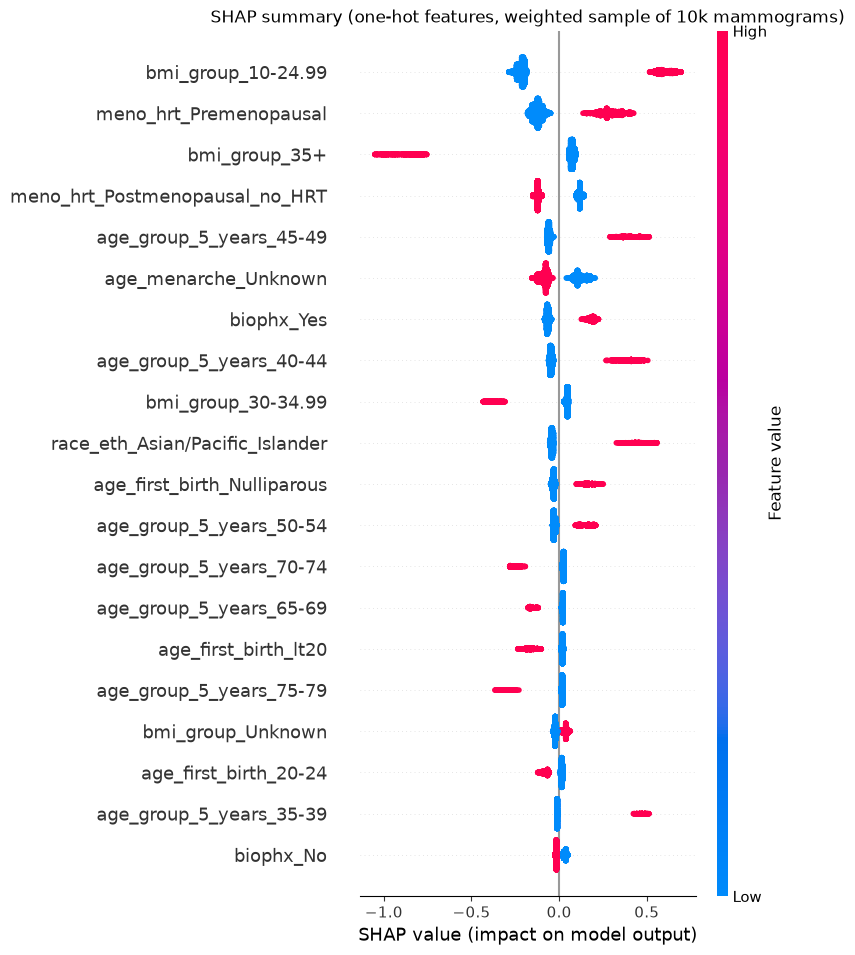

In [9]:
rng = np.random.default_rng(42)
idx = rng.choice(len(test), size=10_000, replace=True, p=w_te / w_te.sum())  # sample mammograms, not patterns
shap.summary_plot(sv_df.iloc[idx].to_numpy(), X_te.iloc[idx], max_display=20, show=False, rng=np.random.default_rng(0))
plt.title("SHAP summary (one-hot features, weighted sample of 10k mammograms)")
plt.gcf().savefig(FIG_DIR / "shap_summary.png", dpi=150, bbox_inches="tight")

### Dependence plots for age group and BMI group

With one-hot inputs a per-column dependence plot only shows 0/1, so here the x-axis is the category and the y-axis
the variable's total SHAP value. Points are coloured by the other variable to show interaction.

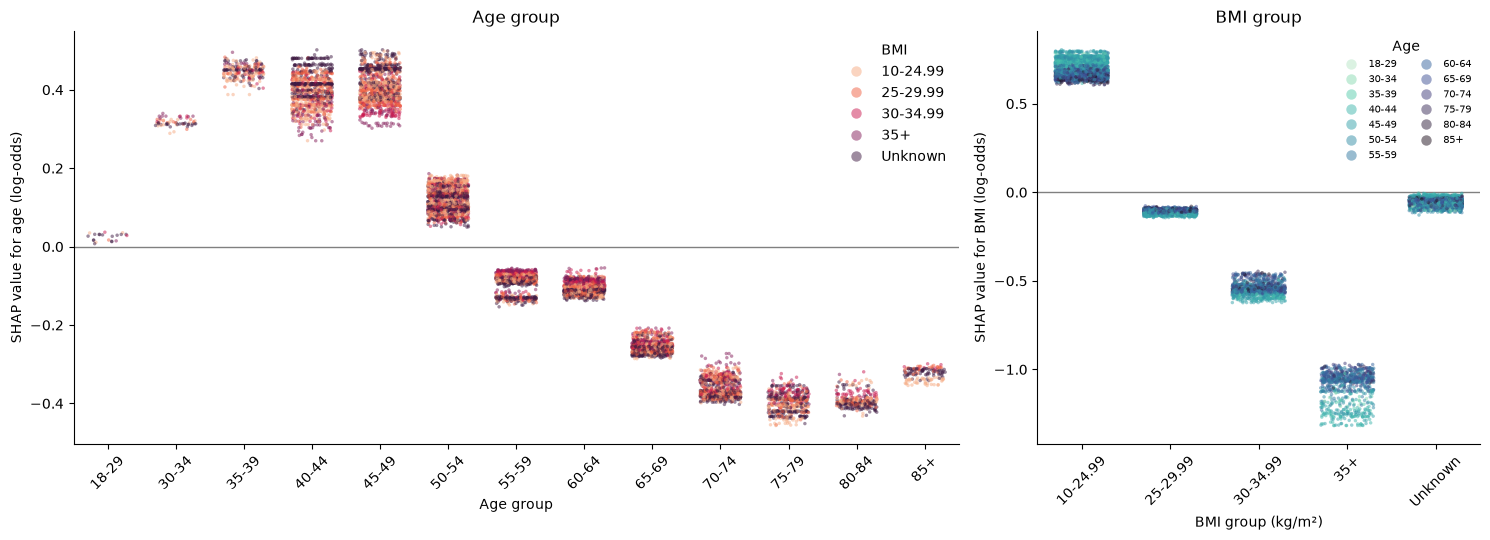

In [10]:
def category_of(var):
    cols = [c for c in FEATURES if VAR_OF[c] == var]
    return X_te[cols].idxmax(axis=1).map(LEVEL_OF)

cats = {v: category_of(v) for v in ("age_group_5_years", "bmi_group")}
sample = pd.DataFrame({"age": cats["age_group_5_years"].iloc[idx].to_numpy(),
                       "bmi": cats["bmi_group"].iloc[idx].to_numpy(),
                       "shap_age": sv_var["age_group_5_years"].iloc[idx].to_numpy(),
                       "shap_bmi": sv_var["bmi_group"].iloc[idx].to_numpy()})
age_order = [LEVEL_OF[c] for c in FEATURES if VAR_OF[c] == "age_group_5_years"]
bmi_order = [LEVEL_OF[c] for c in FEATURES if VAR_OF[c] == "bmi_group"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2, 1]})
sns.stripplot(sample, x="age", y="shap_age", hue="bmi", order=age_order, hue_order=bmi_order,
              palette="rocket_r", size=2.5, alpha=0.5, jitter=0.3, ax=axes[0])
axes[0].set(xlabel="Age group", ylabel="SHAP value for age (log-odds)", title="Age group")
axes[0].legend(title="BMI", markerscale=3, frameon=False)
sns.stripplot(sample, x="bmi", y="shap_bmi", hue="age", order=bmi_order, hue_order=age_order,
              palette="mako_r", size=2.5, alpha=0.5, jitter=0.3, ax=axes[1])
axes[1].set(xlabel="BMI group (kg/m²)", ylabel="SHAP value for BMI (log-odds)", title="BMI group")
axes[1].legend(title="Age", markerscale=3, frameon=False, fontsize=7, ncols=2)
for ax in axes:
    ax.axhline(0, c="grey", lw=1)
    ax.tick_params(axis="x", rotation=45)
sns.despine()
fig.tight_layout()
fig.savefig(FIG_DIR / "shap_dependence_age_bmi.png", dpi=150)